# P6: Operasi Morfologi dan Komponen Terhubung (SIMUTEH)
Bagian 3, 4, dan 5. Jalankan dari folder `notebook/` dengan *Restart & Run All*.

### Kode 1.1 (diulang) Persiapan

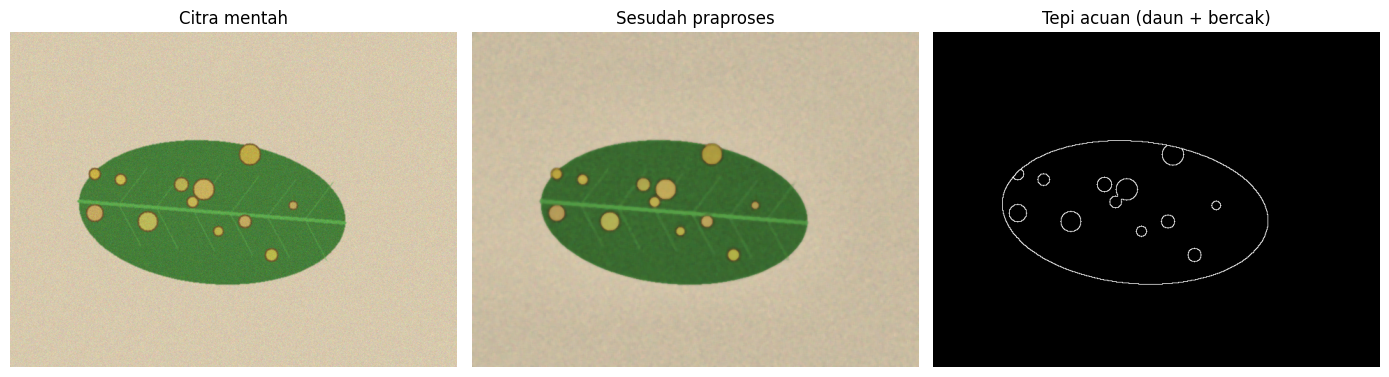

In [1]:
import sys, json
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))   # hasil Evaluasi P1-P4
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

### Fungsi `tepi_canny` (dari Kode 1.3)

In [2]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

## Bagian 3. Operasi Morfologi pada Citra Biner
**Langkah 3.1 (lembar hitung manual, tulis tangan)**: tidak ada kode.

### Kode 3.1 Mask daun awal dan bercak awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.995                    89              11           0.555
1  teh_021.png          0.998                    81               2           0.089
2  teh_011.png          0.996                   146               0               -


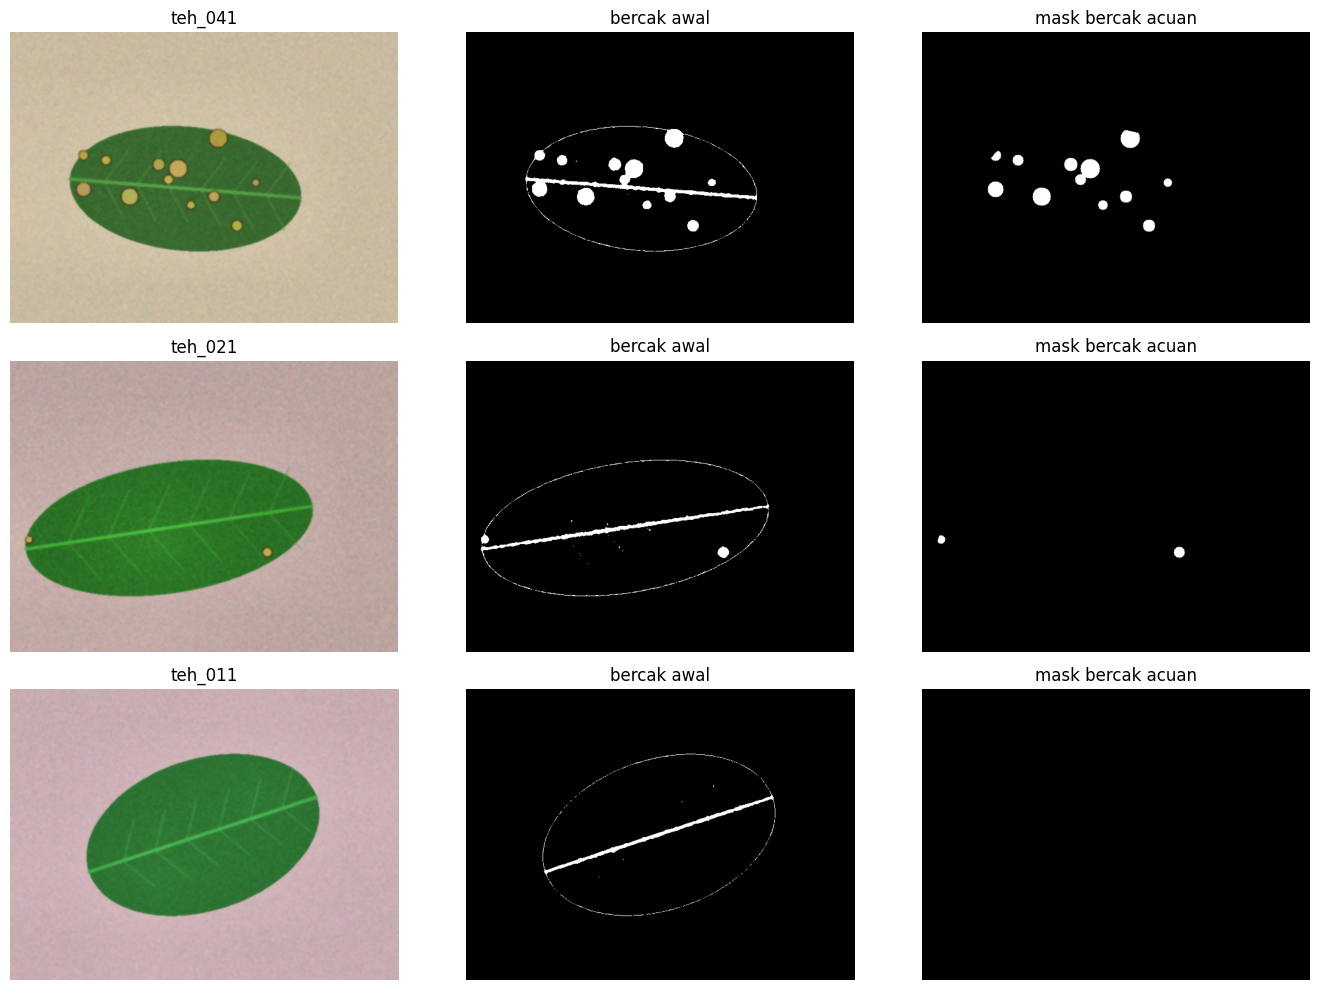

In [3]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:     # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

### Kode 3.2 Erosi, dilasi, opening, dan closing

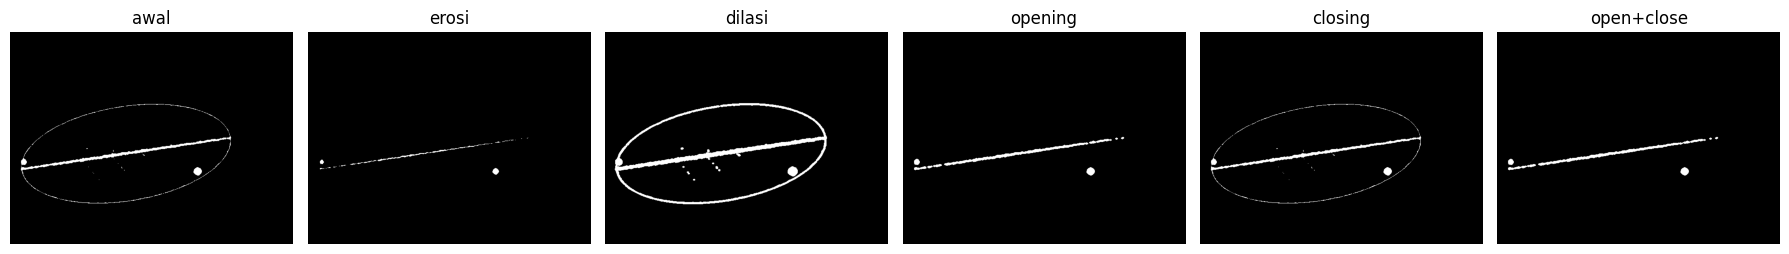

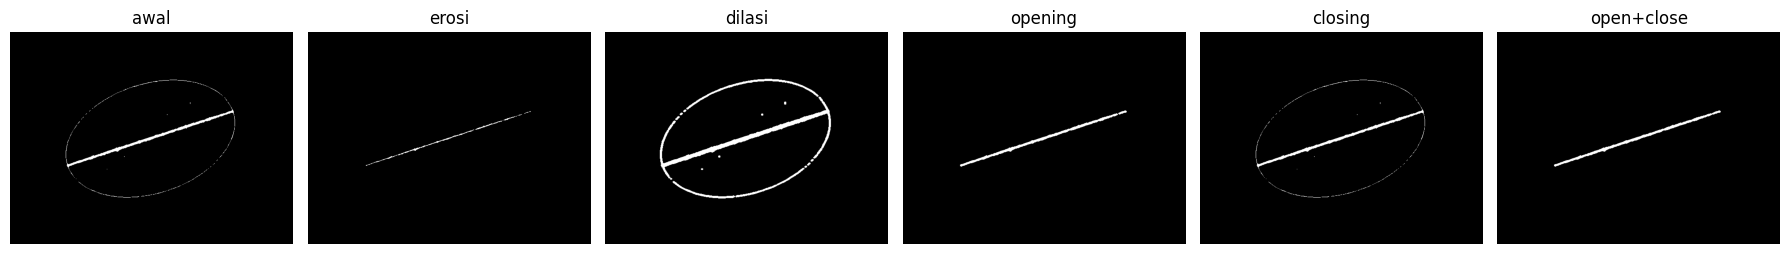

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal        81    4209  0.089
1   teh_021.png       erosi        24     980  0.198
2   teh_021.png      dilasi         9   10955  0.035
3   teh_021.png     opening         9    2927  0.128
4   teh_021.png     closing        74    4247  0.089
5   teh_021.png  open+close         6    2941  0.128
6   teh_011.png        awal       146    3011      -
7   teh_011.png       erosi        10     723      -
8   teh_011.png      dilasi        14    8521      -
9   teh_011.png     opening         2    2233      -
10  teh_011.png     closing       142    3032      -
11  teh_011.png  open+close         1    2246      -


In [4]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3)); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

### Kode 3.3 Eksperimen k, bentuk, dan ukuran SE (bahan Tabel 9)

In [5]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.62   0.12        13.10  22.45  20.40
          5       0.66   0.17         4.30   4.50   6.00
          7       0.73   0.32         2.90   4.60   3.30
  persegi 3       0.63   0.13         7.50  10.65   8.95
          5       0.69   0.24         2.65   4.50   4.85
          7       0.81   0.47         1.35   1.85   1.50
  silang  3       0.62   0.12        13.10  22.45  20.40
          5       0.66   0.17         6.10   7.40   8.70
          7       0.74   0.31         5.00   8.60   6.35
4 elips   3       0.68   0.20         6.25  15.30  13.10
          5       0.71   0.29         3.95   6.65   4.80
          7       0.79   0.47         1.95   2.80   2.35
  persegi 3       0.69   0.22         3.95   8.05   8.60
          5       0.75   0.38         2.75   3.30   3.75
          7       0.82   0.51  

### Kode 3.4 Gradien morfologi dibandingkan dengan Canny

In [6]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))     # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
        .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.984     0.896
gelap                          0.994     0.886
kontras_rendah                 0.622     0.882
normal                         0.989     0.849
terang                         0.990     0.902


### Langkah 3.6 (Kerjakan sendiri) Panel elemen SE

persegi 3x3:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

persegi 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

persegi 7x7:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]

elips 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

elips 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

elips 7x7:
[[0 0 0 1 0 0 0]
 [0 1 1 1 1 1 0]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [0 1 1 1 1 1 0]
 [0 0 0 1 0 0 0]]

silang 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

silang 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

silang 7x7:
[[0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [1 1 1 1 1 1 1]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0]]



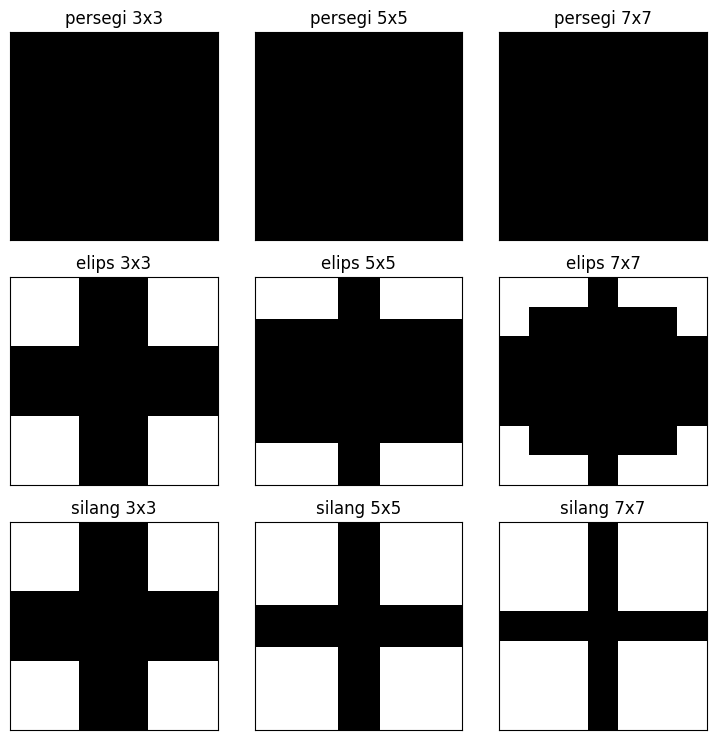

In [7]:
# Langkah 3.6 (Kerjakan sendiri): elemen SE persegi, elips, silang berukuran 3, 5, 7
nama_bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
fig, ax = plt.subplots(3, 3, figsize=(7.5, 7.5))
for i, (nb, kb) in enumerate(nama_bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(kb, (uk, uk))
        ax[i, j].imshow(se, cmap="gray_r", vmin=0, vmax=1)
        ax[i, j].set_title(f"{nb} {uk}x{uk}"); ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        print(f"{nb} {uk}x{uk}:\n{se}\n")
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 4. Komponen Terhubung dan Pengukuran Bercak
**Langkah 4.1 (lembar hitung manual, tulis tangan)**: tidak ada kode.

### Kode 4.1 Komponen terhubung dan pengukuran setiap bercak (bahan Tabel 10)

konektivitas 4: 8 komponen
konektivitas 8: 8 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1      767    146.81        101.3       0.94         1.00  342  174
1      2      241     46.13         55.2       0.99         1.00  120  203
2      3      230     44.02         54.0       0.99         1.00  157  211
3      4      342     65.46         66.8       0.96         1.00  244  217
4      5     4718    903.05       1120.9       0.05         5.23  255  254
5      6      121     23.16         38.4       1.03         1.09  405  247
6      7      164     31.39         45.8       0.98         1.08  298  284
7      8      286     54.74         60.3       0.99         1.00  374  319


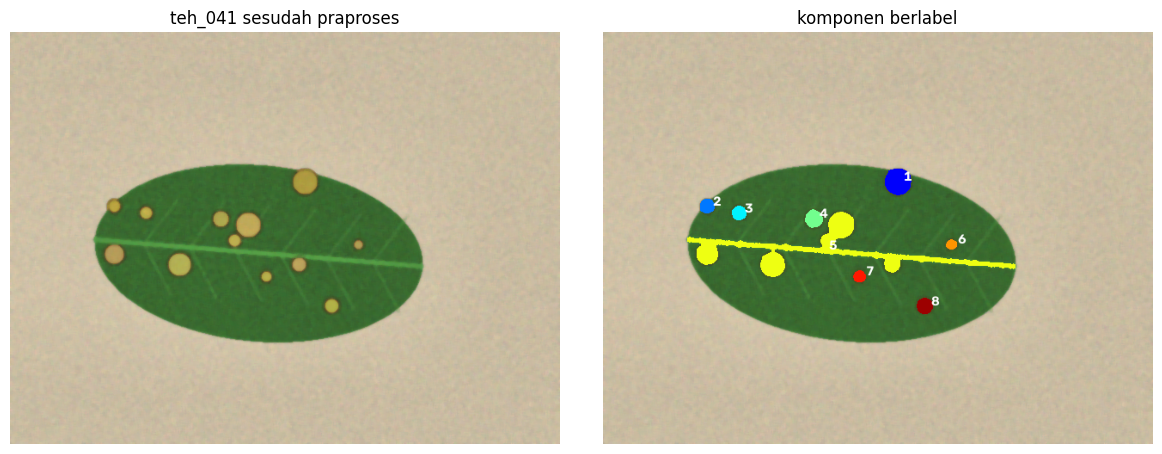

In [8]:
MM_PER_PX = 0.4375            # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
                      round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
tabel_kom.to_csv("../hasil/p6_ukuran_bercak_teh041.csv", index=False)

### Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk (bahan Tabel 11)

In [9]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.95    2.80   2.60
luas + kebulatan + rasio   1.40    1.15   1.25
luas >= 20                 3.10    4.75   3.75
tanpa saring               3.95    6.65   4.80
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan            13
luas + kebulatan + rasio    11
luas >= 20                  17
tanpa saring                19
Name: palsu, dtype: int64


### Langkah 4.4 (Kerjakan sendiri) Diagram sebar komponen benar dan palsu

benar                False    True 
luas_px     count   312.00   183.00
            mean    197.82   397.87
            std     570.90   433.81
            min       1.00    30.00
            25%      22.00   149.50
            50%      34.00   297.00
            75%      77.50   548.00
            max    4127.00  4718.00
kebulatan   count   312.00   183.00
            mean      0.73     0.93
            std       0.40     0.15
            min       0.00     0.05
            25%       0.35     0.92
            50%       0.85     0.96
            75%       1.13     0.99
            max       1.15     1.11
rasio_aspek count   312.00   183.00
            mean      4.82     1.14
            std       8.98     0.40
            min       0.00     1.00
            25%       1.25     1.00
            50%       1.88     1.04
            75%       3.87     1.09
            max      57.32     5.23


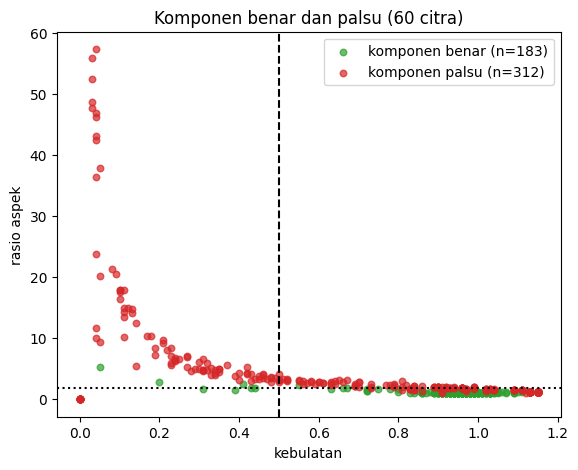

In [10]:
# Langkah 4.4 (Kerjakan sendiri): dasar ambang penyaringan (kebulatan vs rasio aspek)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tabel_k, lbl = ukur_komponen(bersih)
    for _, r in tabel_k.iterrows():
        di_acuan = (mb[lbl == r.label] > 0).mean()            # porsi piksel komponen di mask acuan
        baris.append([d.nama_file, r.luas_px, r.kebulatan, r.rasio_aspek, di_acuan > 0.5])
kom = pd.DataFrame(baris, columns=["citra", "luas_px", "kebulatan", "rasio_aspek", "benar"])
print(kom.groupby("benar")[["luas_px", "kebulatan", "rasio_aspek"]].describe().round(2).T)

plt.figure(figsize=(6.5, 5))
for nilai, warna_, nama_ in [(True, "tab:green", "komponen benar"), (False, "tab:red", "komponen palsu")]:
    s = kom[kom.benar == nilai]
    plt.scatter(s.kebulatan, s.rasio_aspek, c=warna_, s=22, alpha=0.7, label=f"{nama_} (n={len(s)})")
plt.axvline(0.5, ls="--", c="k"); plt.axhline(1.8, ls=":", c="k")
plt.xlabel("kebulatan"); plt.ylabel("rasio aspek"); plt.legend()
plt.title("Komponen benar dan palsu (60 citra)")
plt.savefig("../hasil/p6_sebar_komponen.png", dpi=150, bbox_inches="tight")
plt.show()

## Bagian 5. Integrasi: Modul `src/bercak.py`
Modul `bercak.py` (tujuh TODO) ada di `src/bercak.py`. Notebook ini hanya memanggil dan mengevaluasinya.

### Kode 5.2 Evaluasi modul bercak.py (bahan Tabel 12)

Galat absolut rerata persen bercak: 0.504
Korelasi persen prediksi vs acuan  : 0.928
Akurasi kelas                      : 0.917
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             20              0      0
Bercak Ringan             0             19      1
Sehat                     0              4     16
kondisi
bayangan          1.00
gelap             0.92
kontras_rendah    0.83
normal            0.92
terang            0.92
Name: benar, dtype: float64


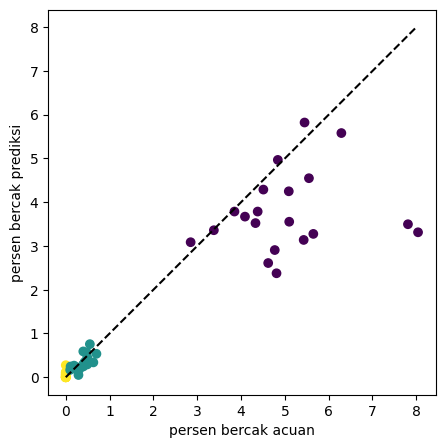

In [11]:
import importlib, bercak
importlib.reload(bercak)
PB = {}                                    # ubah parameter sesuai temuan Anda
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan  :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas                      :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_scatter_persen.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# Bahan Tabel 12: jumlah daun sehat dinilai berbercak, dan daun berbercak dinilai sehat
sehat_palsu = int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum())
berbercak_lolos = int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum())
kond_terendah = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().idxmin()
print("Daun sehat dinilai berbercak :", sehat_palsu)
print("Daun berbercak dinilai sehat :", berbercak_lolos)
print("Kondisi cahaya akurasi terendah:", kond_terendah)

Daun sehat dinilai berbercak : 4
Daun berbercak dinilai sehat : 1
Kondisi cahaya akurasi terendah: kontras_rendah


### Langkah 5.3 (Kerjakan sendiri) Analisis kesalahan

5 citra salah kelas dari 60
       nama        kondisi  persen_acuan  persen_prediksi   kelas_acuan kelas_prediksi  jumlah_acuan  jumlah_prediksi
teh_014.png kontras_rendah          0.00            0.102         Sehat  Bercak Ringan             0                2
teh_016.png         normal          0.00            0.112         Sehat  Bercak Ringan             0                3
teh_017.png          gelap          0.00            0.275         Sehat  Bercak Ringan             0                7
teh_019.png kontras_rendah          0.00            0.106         Sehat  Bercak Ringan             0                3
teh_028.png         terang          0.29            0.051 Bercak Ringan          Sehat             1                2


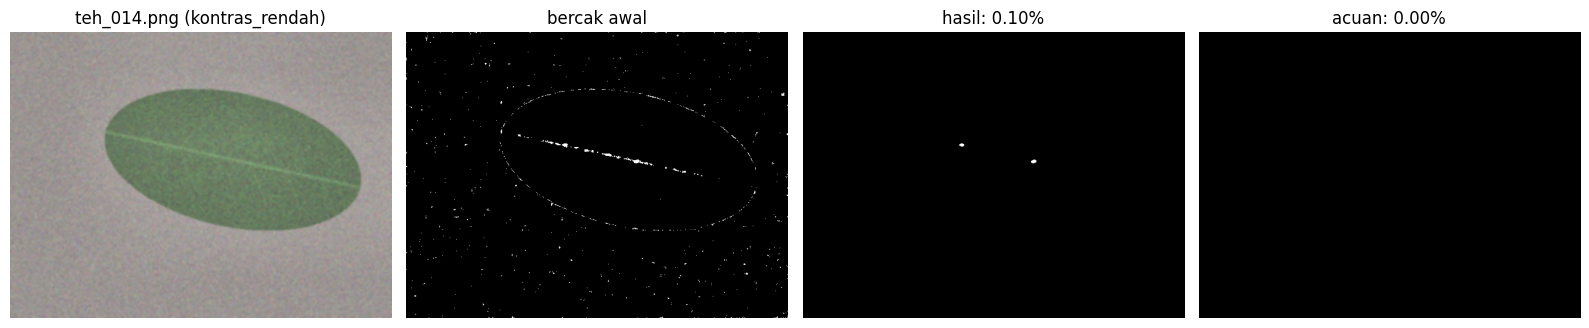

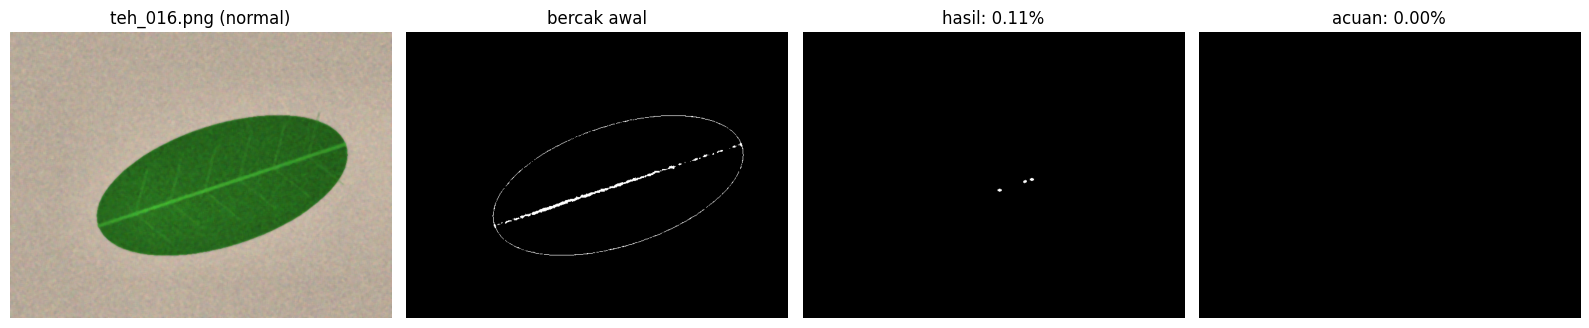

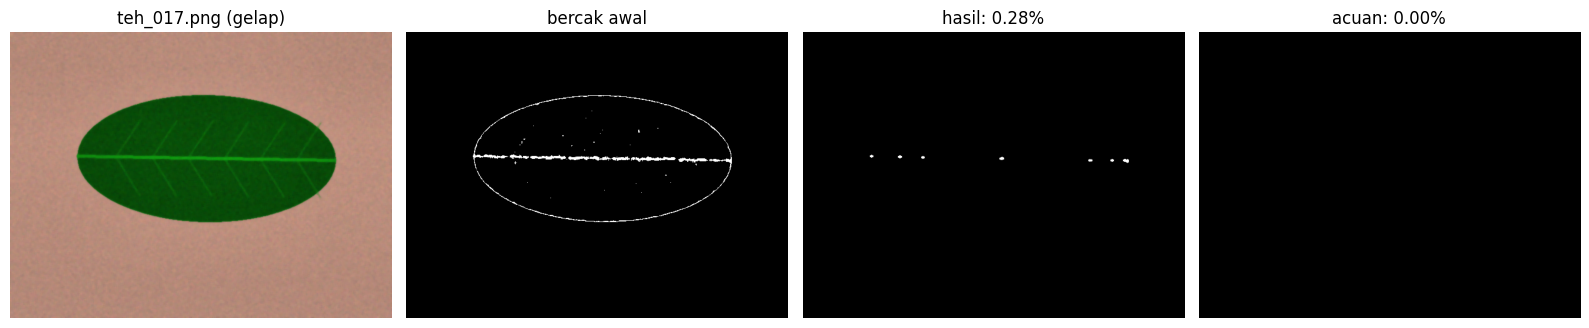

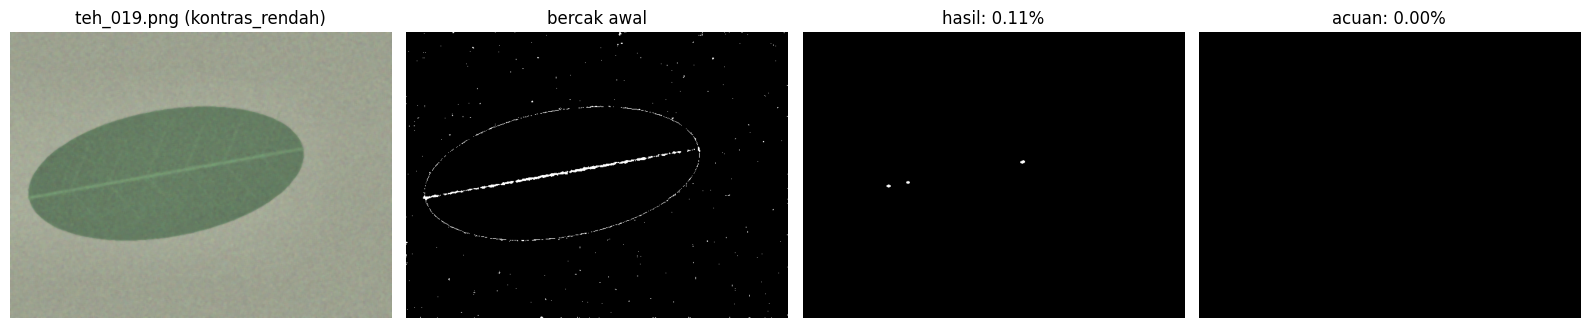

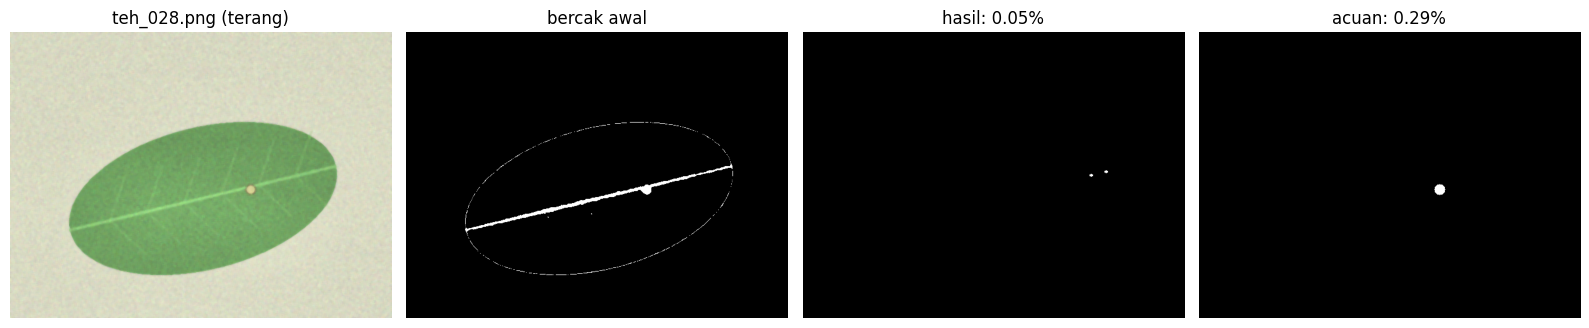

In [13]:
# Langkah 5.3 (Kerjakan sendiri): analisis kesalahan. Tampilkan citra yang salah kelas
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(f"{len(salah)} citra salah kelas dari {len(ev)}")
print(salah[["nama", "kondisi", "persen_acuan", "persen_prediksi", "kelas_acuan", "kelas_prediksi",
             "jumlah_acuan", "jumlah_prediksi"]].to_string(index=False))
for _, d in salah.iterrows():
    img, md, mb = muat(d.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    b0 = bercak_awal(pra_, h["mask_daun"], kanal=2, k=4.0)
    tampil([pra_, b0, h["mask_bercak"], mb],
           [f"{d.nama} ({d.kondisi})", "bercak awal", f"hasil: {d.persen_prediksi:.2f}%", f"acuan: {d.persen_acuan:.2f}%"],
           ukuran=(16, 3.4))
    plt.show()

### Langkah 5.4 Justifikasi parameter (Tabel 13)

In [14]:
# Langkah 5.4: parameter final yang tersimpan
print(open("../hasil/param_bercak.json").read())

{
  "kanal": 2,
  "k": 4.0,
  "se_bentuk": "elips",
  "se_open": 5,
  "se_close": 5,
  "luas_min": 20,
  "bulat_min": 0.5,
  "rasio_maks": 1.8,
  "batas_ringan": 0.1,
  "batas_berat": 2.0,
  "mm_per_px": 0.4375
}


### Langkah 5.5 Reproduksibilitas
Jalankan ulang dengan *Restart & Run All*, perbarui `README.md`, commit, lalu `git tag v0.3-morfologi` dan `git push --tags`.